GAN folder exists: True
Diffusion folder exists: True
Real image folder exists: True
GAN samples: 38
Diffusion samples: 17
Real images available: 6233
GAN: evaluated 38, errors 0
Diffusion: evaluated 17, errors 0
Real reference: evaluated 500, errors 0

GROUP METRIC SUMMARY


,group,n_images,brightness_mean,brightness_std,contrast_mean,contrast_std,dynamic_range_mean,dynamic_range_std,gradient_energy_mean,gradient_energy_std,laplacian_variance_mean,laplacian_variance_std,high_frequency_residual_mean,high_frequency_residual_std
0,GAN,38,132.5454,14.8501,49.5577,10.0387,233.0789,16.8326,832.1678,295.5868,6591.9592,1494.4285,13.0450,2.0942
1,Diffusion,17,125.9060,7.8537,27.9879,5.2938,174.8235,24.6940,141.0600,98.6377,750.1502,348.5438,4.7686,0.8312
2,Real reference,500,147.8298,23.4428,61.3424,8.2831,254.4060,3.8117,171.3417,65.8491,758.5965,259.4946,3.8749,0.7084


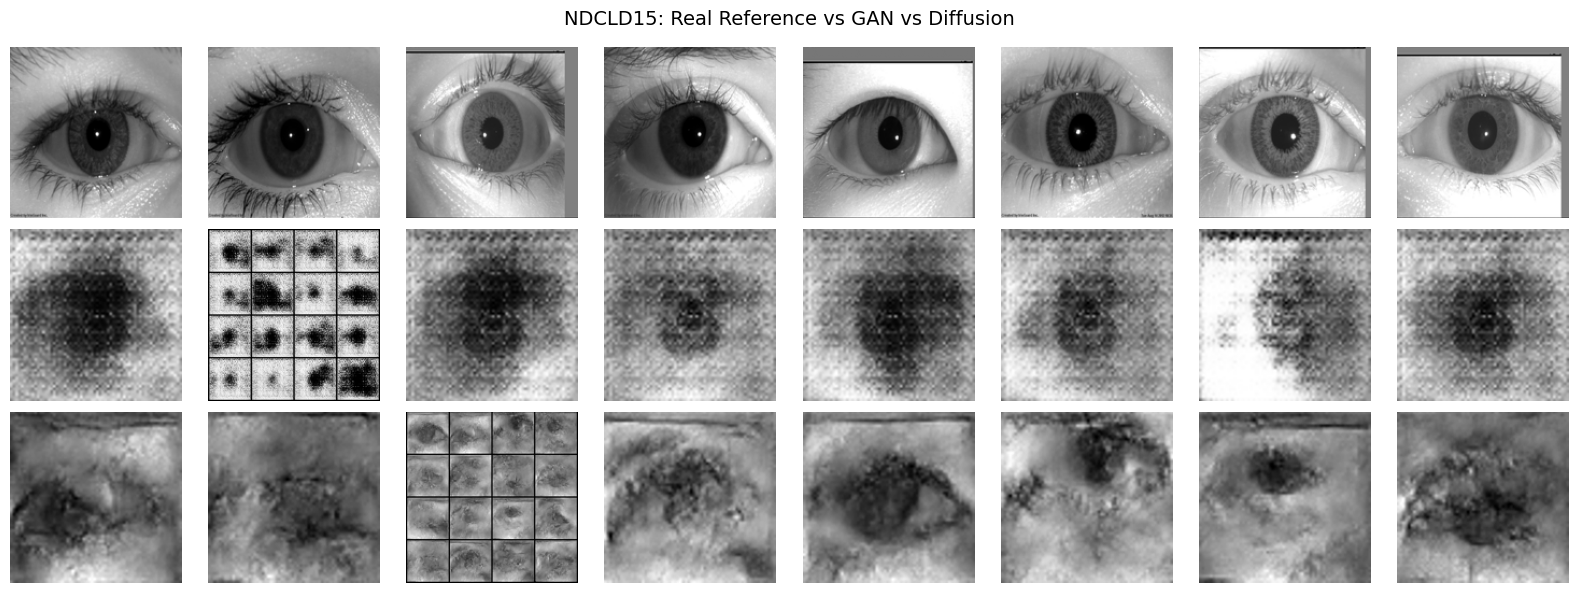

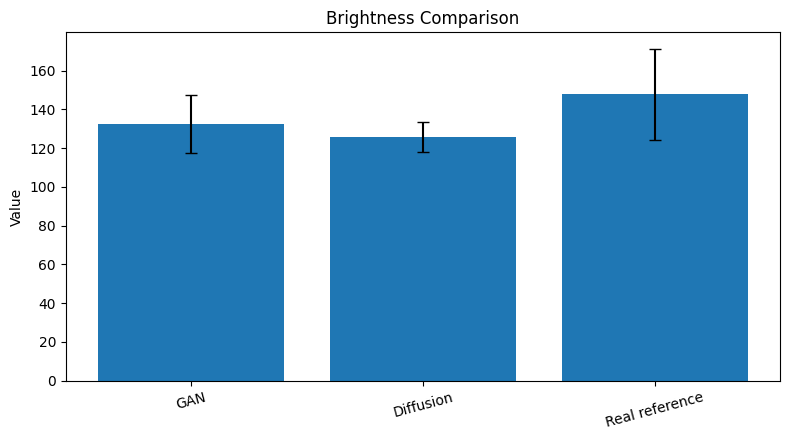

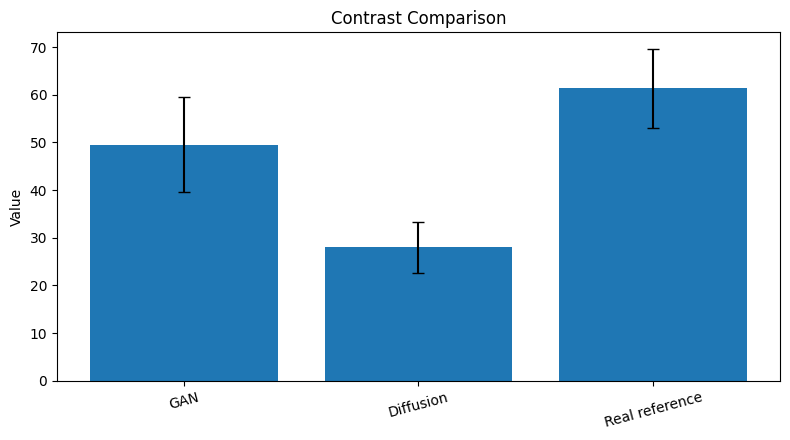

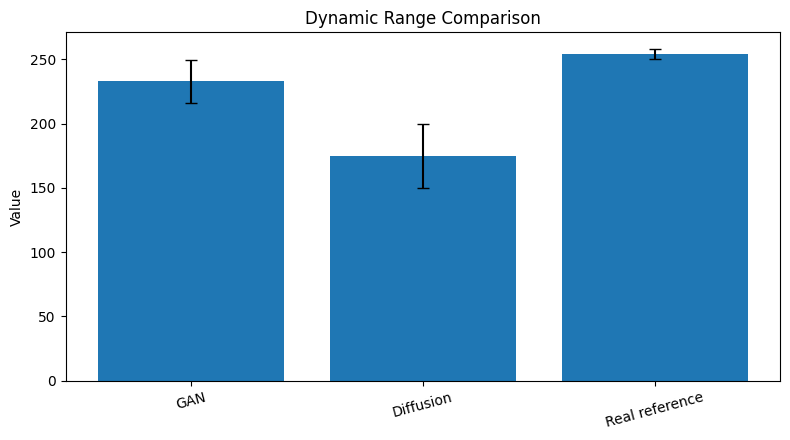

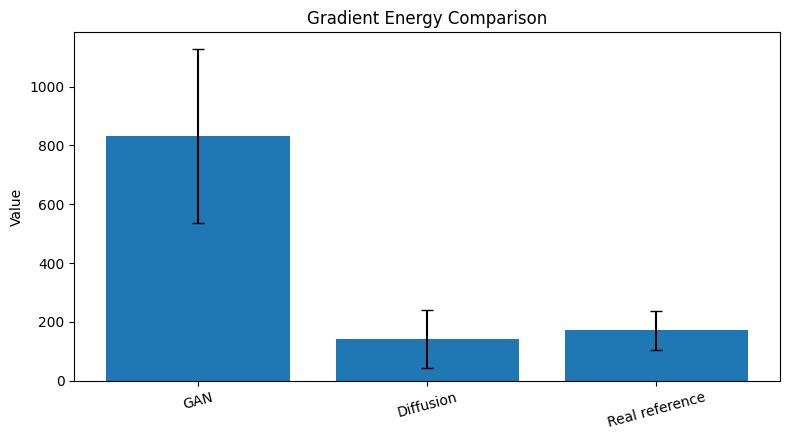

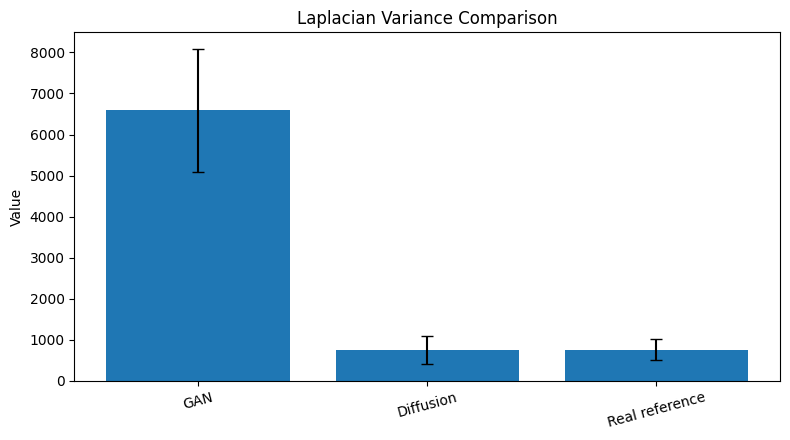

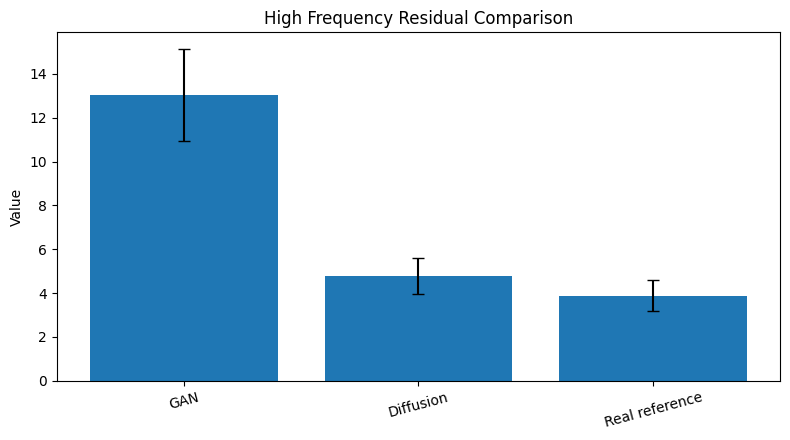


NOTEBOOK 11 COMPLETED
Output folder: /kaggle/working/nd_iris_project/notebook11_gan_vs_diffusion
ZIP: /kaggle/working/nd_iris_project/ND_Iris_Notebook11_Results.zip
ZIP files: 13
ZIP integrity: PASSED
Conclusion file: /kaggle/working/nd_iris_project/notebook11_gan_vs_diffusion/Notebook11_Conclusion.md
Elapsed seconds: 4.68

GROUP SUMMARY


,group,n_images,brightness_mean,brightness_std,contrast_mean,contrast_std,dynamic_range_mean,dynamic_range_std,gradient_energy_mean,gradient_energy_std,laplacian_variance_mean,laplacian_variance_std,high_frequency_residual_mean,high_frequency_residual_std
0,GAN,38,132.5454,14.8501,49.5577,10.0387,233.0789,16.8326,832.1678,295.5868,6591.9592,1494.4285,13.0450,2.0942
1,Diffusion,17,125.9060,7.8537,27.9879,5.2938,174.8235,24.6940,141.0600,98.6377,750.1502,348.5438,4.7686,0.8312
2,Real reference,500,147.8298,23.4428,61.3424,8.2831,254.4060,3.8117,171.3417,65.8491,758.5965,259.4946,3.8749,0.7084



METRIC INTERPRETATION


,metric,interpretation
0,brightness,GAN has the higher mean brightness (132.5454 G...
1,contrast,GAN has the higher mean contrast (49.5577 GAN ...
2,dynamic_range,GAN has the higher mean dynamic range (233.078...
3,gradient_energy,GAN has the higher mean gradient energy (832.1...
4,laplacian_variance,GAN has the higher mean laplacian variance (65...
5,high_frequency_residual,GAN has the higher mean high frequency residua...



Next: send me the final output and summary table.


In [16]:

# ============================================================
# NOTEBOOK 11: GAN vs DIFFUSION COMPARISON
# Dataset: NDCLD15 / ND-Iris
# ============================================================

from pathlib import Path
from PIL import Image, ImageOps
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json, time, shutil, zipfile, hashlib, random

# -------------------- CONFIGURATION --------------------------
PROJECT = Path("/kaggle/working/nd_iris_project")

GAN_DIR = PROJECT / "notebook06_gan_augmentation/generated_samples"
DIFF_DIR = PROJECT / "notebook07_diffusion_training/generated_samples"
REAL_DIR = PROJECT / "notebook02_preprocessing/images_224"

OUT = PROJECT / "notebook11_gan_vs_diffusion"
OUT.mkdir(parents=True, exist_ok=True)

random.seed(42)
np.random.seed(42)
start_time = time.time()

print("GAN folder exists:", GAN_DIR.exists())
print("Diffusion folder exists:", DIFF_DIR.exists())
print("Real image folder exists:", REAL_DIR.exists())

# -------------------- IMAGE DISCOVERY ------------------------
EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def discover_images(folder):
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    )

gan_files = discover_images(GAN_DIR)
diff_files = discover_images(DIFF_DIR)
real_files = discover_images(REAL_DIR)

print(f"GAN samples: {len(gan_files)}")
print(f"Diffusion samples: {len(diff_files)}")
print(f"Real images available: {len(real_files)}")

if not gan_files:
    raise FileNotFoundError(f"No GAN images found in {GAN_DIR}")
if not diff_files:
    raise FileNotFoundError(f"No diffusion images found in {DIFF_DIR}")

# -------------------- METRIC FUNCTIONS -----------------------
def image_metrics(path):
    """Low-level image statistics; not a semantic quality score."""
    with Image.open(path) as im:
        im = ImageOps.grayscale(im)
        im.thumbnail((256, 256))
        arr = np.asarray(im, dtype=np.float32)

    brightness = float(arr.mean())
    contrast = float(arr.std())
    dynamic_range = float(arr.max() - arr.min())

    # Gradient-energy proxy
    gx = np.diff(arr, axis=1) if arr.shape[1] > 1 else np.zeros_like(arr)
    gy = np.diff(arr, axis=0) if arr.shape[0] > 1 else np.zeros_like(arr)
    gradient_energy = float(
        (np.mean(gx**2) + np.mean(gy**2)) / 2
    )

    # Laplacian-variance sharpness proxy
    padded = np.pad(arr, 1, mode="edge")
    lap = (
        padded[:-2, 1:-1] + padded[2:, 1:-1]
        + padded[1:-1, :-2] + padded[1:-1, 2:]
        - 4 * arr
    )
    laplacian_variance = float(np.var(lap))

    # High-frequency residual proxy
    smooth = np.asarray(
        Image.fromarray(arr.astype(np.uint8)).filter(
            __import__("PIL").ImageFilter.GaussianBlur(radius=1.0)
        ),
        dtype=np.float32
    )
    high_frequency_residual = float(np.mean(np.abs(arr - smooth)))

    return {
        "brightness": brightness,
        "contrast": contrast,
        "dynamic_range": dynamic_range,
        "gradient_energy": gradient_energy,
        "laplacian_variance": laplacian_variance,
        "high_frequency_residual": high_frequency_residual
    }

def evaluate_group(files, group_name):
    rows = []
    errors = 0

    for path in files:
        try:
            row = image_metrics(path)
            row["group"] = group_name
            row["filename"] = path.name
            rows.append(row)
        except Exception as e:
            errors += 1

    return rows, errors

# Evaluate every generated image; sample real images for reference.
MAX_REAL = min(500, len(real_files))
real_subset = random.sample(real_files, MAX_REAL) if MAX_REAL else []

all_rows = []
error_counts = {}

for name, files in [
    ("GAN", gan_files),
    ("Diffusion", diff_files),
    ("Real reference", real_subset)
]:
    rows, errors = evaluate_group(files, name)
    all_rows.extend(rows)
    error_counts[name] = errors
    print(f"{name}: evaluated {len(rows)}, errors {errors}")

metrics_df = pd.DataFrame(all_rows)
metrics_path = OUT / "per_image_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

# -------------------- SUMMARY STATISTICS ---------------------
metric_cols = [
    "brightness", "contrast", "dynamic_range",
    "gradient_energy", "laplacian_variance",
    "high_frequency_residual"
]

summary_rows = []
for group in ["GAN", "Diffusion", "Real reference"]:
    subset = metrics_df[metrics_df["group"] == group]
    row = {"group": group, "n_images": len(subset)}

    for metric in metric_cols:
        row[f"{metric}_mean"] = (
            float(subset[metric].mean()) if len(subset) else None
        )
        row[f"{metric}_std"] = (
            float(subset[metric].std(ddof=0)) if len(subset) else None
        )

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_path = OUT / "group_metric_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nGROUP METRIC SUMMARY")
display(summary_df.round(4))

# -------------------- SAMPLE COMPARISON GRID ------------------
def load_display_image(path, size=(160, 160)):
    with Image.open(path) as im:
        im = ImageOps.grayscale(im)
        im = ImageOps.fit(im, size)
        return im.copy()

rng = random.Random(42)
gan_show = rng.sample(gan_files, min(8, len(gan_files)))
diff_show = rng.sample(diff_files, min(8, len(diff_files)))
real_show = rng.sample(real_files, min(8, len(real_files))) if real_files else []

ncols = 8
fig, axes = plt.subplots(3, ncols, figsize=(16, 6))
fig.suptitle("NDCLD15: Real Reference vs GAN vs Diffusion", fontsize=14)

for row_idx, (name, files) in enumerate([
    ("Real reference", real_show),
    ("GAN", gan_show),
    ("Diffusion", diff_show)
]):
    for col_idx in range(ncols):
        ax = axes[row_idx, col_idx]
        ax.axis("off")
        if col_idx < len(files):
            ax.imshow(load_display_image(files[col_idx]), cmap="gray")
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=10)

plt.tight_layout()
sample_grid_path = OUT / "sample_comparison_grid.png"
plt.savefig(sample_grid_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# -------------------- METRIC COMPARISON PLOTS ----------------
plot_paths = []
for metric in metric_cols:
    fig, ax = plt.subplots(figsize=(8, 4.5))

    labels, means, stds = [], [], []
    for _, row in summary_df.iterrows():
        if pd.notna(row[f"{metric}_mean"]):
            labels.append(row["group"])
            means.append(row[f"{metric}_mean"])
            stds.append(row[f"{metric}_std"])

    ax.bar(labels, means, yerr=stds, capsize=4)
    ax.set_title(f"{metric.replace('_', ' ').title()} Comparison")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=15)
    fig.tight_layout()

    plot_path = OUT / f"{metric}_comparison.png"
    fig.savefig(plot_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    plot_paths.append(plot_path)

# -------------------- INTERPRETATION -------------------------
gan_summary = summary_df[summary_df["group"] == "GAN"]
diff_summary = summary_df[summary_df["group"] == "Diffusion"]
real_summary = summary_df[summary_df["group"] == "Real reference"]

def get_value(frame, col):
    if frame.empty or pd.isna(frame.iloc[0][col]):
        return None
    return float(frame.iloc[0][col])

interpretation = []
for metric in metric_cols:
    g = get_value(gan_summary, f"{metric}_mean")
    d = get_value(diff_summary, f"{metric}_mean")
    r = get_value(real_summary, f"{metric}_mean")

    if g is None or d is None:
        statement = "Insufficient valid samples for comparison."
    else:
        higher = "GAN" if g > d else ("Diffusion" if d > g else "Equal")
        statement = (
            f"{higher} has the higher mean {metric.replace('_', ' ')} "
            f"({g:.4f} GAN vs {d:.4f} diffusion)."
        )
        if r is not None:
            statement += f" Real-reference mean: {r:.4f}."

    interpretation.append({"metric": metric, "interpretation": statement})

interpretation_df = pd.DataFrame(interpretation)
interpretation_df.to_csv(OUT / "metric_interpretation.csv", index=False)

# -------------------- OPTIONAL TRAINING HISTORY ---------------
# Include existing history files if available; no assumption about schema.
history_candidates = [
    PROJECT / "notebook06_gan_augmentation",
    PROJECT / "notebook07_diffusion_training"
]

history_records = []
for folder in history_candidates:
    for p in folder.rglob("*.csv"):
        try:
            df = pd.read_csv(p)
            if not df.empty:
                history_records.append({
                    "source_file": str(p),
                    "rows": len(df),
                    "columns": ", ".join(map(str, df.columns))
                })
        except Exception:
            pass

pd.DataFrame(history_records).to_csv(
    OUT / "available_training_history_files.csv", index=False
)

# -------------------- REPORT / CONCLUSION FILE ----------------
elapsed = time.time() - start_time

report = {
    "notebook": "11 - GAN vs Diffusion Comparison",
    "dataset": "NDCLD15 / ND-Iris",
    "gan_images_found": len(gan_files),
    "diffusion_images_found": len(diff_files),
    "real_reference_images_evaluated": len(real_subset),
    "metric_images_evaluated": len(metrics_df),
    "errors_by_group": error_counts,
    "metrics": metric_cols,
    "elapsed_seconds": round(elapsed, 2),
    "limitations": [
        "No verified ground-truth contact-lens labels are available in this workflow.",
        "GAN and diffusion are unconditional image-generation experiments.",
        "Low-level image statistics do not prove realism, semantic diversity, identity preservation, privacy, or downstream utility.",
        "The generated sample counts may be small and unequal; conclusions are exploratory.",
        "Higher contrast, gradient energy, or sharpness is not automatically better."
    ]
}

with open(OUT / "comparison_report.json", "w") as f:
    json.dump(report, f, indent=2)

lines = [
    "# Notebook 11 — GAN vs Diffusion Comparison",
    "",
    "## Experimental setup",
    f"- GAN generated images found: **{len(gan_files)}**",
    f"- Diffusion generated images found: **{len(diff_files)}**",
    f"- Real reference images evaluated: **{len(real_subset)}**",
    f"- Total images successfully evaluated: **{len(metrics_df)}**",
    f"- Evaluation errors: **{sum(error_counts.values())}**",
    "",
    "## Measured results",
    summary_df.round(4).to_markdown(index=False),
    "",
    "## Metric interpretation",
]
for item in interpretation:
    lines.append(f"- **{item['metric']}**: {item['interpretation']}")

lines += [
    "",
    "## Important limitations",
    "- These are low-level image-statistics proxies, not a validated image-quality benchmark.",
    "- A higher metric value does not necessarily indicate a better generated image.",
    "- Visual similarity and semantic diversity have not been validated by expert review or a pretrained feature-space metric.",
    "- No verified labels are available here to establish contact-lens classification or iris identity performance.",
    "- Unequal and small generated sample counts limit the strength of the comparison.",
    "",
    "## Conclusion",
    "This notebook compares the available GAN and diffusion samples using visual grids and "
    "low-level grayscale image statistics. The numeric results describe only the evaluated "
    "files and do not establish that either generator is superior in realism, diversity, "
    "identity preservation, privacy, or downstream recognition utility. Use the actual "
    "summary table and plots when reporting results."
]

conclusion_path = OUT / "Notebook11_Conclusion.md"
conclusion_path.write_text("\n".join(lines), encoding="utf-8")

# -------------------- ZIP ALL NOTEBOOK 11 RESULTS -------------
zip_path = PROJECT / "ND_Iris_Notebook11_Results.zip"
if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(Path("notebook11_gan_vs_diffusion") / p.relative_to(OUT)))

# -------------------- ZIP VALIDATION --------------------------
with zipfile.ZipFile(zip_path, "r") as zf:
    bad_file = zf.testzip()
    zip_count = len(zf.namelist())

print("\n" + "=" * 60)
print("NOTEBOOK 11 COMPLETED")
print("=" * 60)
print("Output folder:", OUT)
print("ZIP:", zip_path)
print("ZIP files:", zip_count)
print("ZIP integrity:", "PASSED" if bad_file is None else f"FAILED: {bad_file}")
print("Conclusion file:", conclusion_path)
print("Elapsed seconds:", round(time.time() - start_time, 2))

print("\nGROUP SUMMARY")
display(summary_df.round(4))

print("\nMETRIC INTERPRETATION")
display(interpretation_df)

print("\nNext: send me the final output and summary table.")




# Notebook 11 — GAN vs Diffusion Comparison: Conclusion

## Objective
This notebook compared images generated by the GAN and diffusion models using visual inspection and low-level grayscale image statistics, with real NDCLD15 images as a reference.

## Experimental Results
- GAN images evaluated: 38
- Diffusion images evaluated: 17
- Real reference images evaluated: 500
- Total images evaluated: 555
- Image-evaluation errors: 0
- Result ZIP integrity: Passed

### Key Findings
1. **Brightness:** GAN images had a mean brightness of 132.5454, while diffusion images had 125.9060. The real reference mean was 147.8298.
2. **Contrast:** GAN achieved a mean contrast of 49.5577, compared with 27.9879 for diffusion and 61.3424 for real images.
3. **Dynamic range:** GAN achieved 233.0789, diffusion 174.8235, and the real reference 254.4060.
4. **Gradient energy:** GAN recorded 832.1678, diffusion 141.0600, and the real reference 171.3417.
5. **Laplacian variance:** GAN recorded 6591.9592, diffusion 750.1502, and the real reference 758.5965.
6. **High-frequency residual:** GAN recorded 13.0450, diffusion 4.7686, and the real reference 3.8749.

## Conclusion
The evaluated GAN samples exhibited substantially stronger high-frequency responses and edge-related statistics than both the diffusion samples and the real reference images. This may indicate sharper local transitions, excessive texture, or generation artifacts; it does not establish superior image quality.

The diffusion samples had lower brightness and contrast than the real reference images. Their Laplacian variance was numerically close to the real reference mean, but this single statistic cannot establish perceptual similarity or realism.

The results are exploratory because the available generated sample counts were small and unequal. The comparison used low-level image statistics rather than a validated perceptual-quality or semantic-diversity benchmark.

## Limitations
- No verified contact-lens class labels or iris identity ground truth were used.
- Neither model's performance establishes contact-lens classification or biometric recognition accuracy.
- Visual inspection and low-level metrics cannot independently establish semantic diversity, identity preservation, privacy, or downstream utility.
- A more rigorous comparison would require more generated samples, controlled evaluation conditions, and validated perceptual and diversity metrics.

**Final takeaway:** This experiment establishes measurable differences between the available GAN and diffusion samples, but the current evidence is insufficient to declare either generator universally superior.
